In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.Robusted_filas import robust_archetypal_analysis
from src.Robusted_mxnx1 import robust_archetypal_analysis_mxnx1
from src.Robusted_Chen_2D_mxnx1 import robust_archetypal_analysis_huber, robust_archetypal_analysis_huber_mxnx1

np.set_printoptions(precision=4, suppress=True)

In [2]:
# Datos con menor separación entre arquetipos y adición de ruido
rng = np.random.default_rng(42)

# Arquetipos verdaderos más cercanos entre sí
true_Z = np.array([
    [0.0, 0.0],
    [0.4, 0.05],
    [0.15, 0.45]
])

n_samples = 150
true_S = rng.dirichlet(np.ones(3), size=n_samples)
X = true_S @ true_Z

# Añadir un poco de ruido gausiano para que los puntos no sean una mezcla convexa perfecta
X += rng.normal(0, 0.02, size=X.shape)

p = 3
# Definir pesos diferenciados basados en la distancia a uno de los arquetipos
distances = np.linalg.norm(X - true_Z[2], axis=1)
lower_weight_indices = np.argsort(distances)[:30]
weights = np.ones(n_samples)
weights[lower_weight_indices] = 0.8
W = np.diag(weights)

print("Dimensiones de X:", X.shape)
print("Número de arquetipos p:", p)
print("Puntos con peso 1.0:", np.sum(weights == 1.0))
print("Puntos con peso 0.8:", np.sum(weights == 0.8))

Dimensiones de X: (150, 2)
Número de arquetipos p: 3
Puntos con peso 1.0: 120
Puntos con peso 0.8: 30


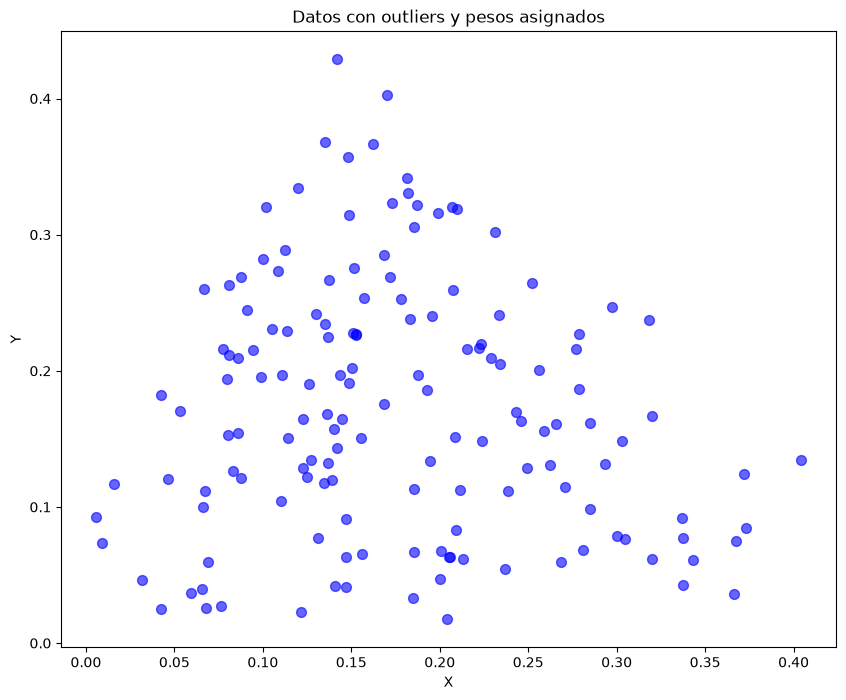

In [3]:
# plot data

plt.figure(figsize=(10, 8))

plt.scatter(X[:, 0], X[:, 1], c='blue', alpha=0.6, s=50)

plt.xlabel('X')
plt.ylabel('Y')
plt.title('Datos con outliers y pesos asignados')

plt.show()

In [4]:
# Métodos

# A) AA-robusto (IRLS con estimadores M / Bisquare de Eugster & Leisch 2011)
C_rob, S_rob, Z_rob, weights_rob = robust_archetypal_analysis(
    W@X, p=p, max_robust_iter=20, max_inner_iter=10, c_factor=2.0, tol=1e-5, w_init=weights,
    random_state=42, verbose=False
)

# B) AA-robusto (IRLS con estimadores M / Bisquare de Eugster & Leisch 2011)
# Ahora capturamos X_weighted_3d como 5º valor devuelto por la función
C_rob_mxnx1, S_rob_mxnx1, Z_rob_mxnx1, weights_rob_mxnx1, X_weighted_3d = robust_archetypal_analysis_mxnx1(
    W @ X, p=p, max_robust_iter=20, max_inner_iter=10, c_factor=2.0, tol=1e-5, w_init=weights,
    random_state=42, verbose=False
)

# C) AA-robusto (Algoritmo 3 de Chen et al. 2014 con pérdida de Huber)
C_rob, S_rob_huber, Z_rob_huber, weights_rob_huber = robust_archetypal_analysis_huber(
    W @ X, p=p, max_robust_iter=20, epsilon=0.01, tol=1e-5,
    random_state=42, verbose=False
)

# D) AA-robusto (Algoritmo 3 de Chen et al. 2014 con formato (m, n, 1))
# Capturamos X_weighted_3d como 5º valor devuelto
C_rob_mxnx1, S_rob_huber_mxnx1, Z_rob_huber_mxnx1, weights_rob_huber_mxnx1, X_weighted_3d_huber = robust_archetypal_analysis_huber_mxnx1(
    W @ X, p=p, max_robust_iter=20, epsilon=0.01, tol=1e-5,
    random_state=42, verbose=False
)

print("Ejecución completada.")

Ejecución completada.


In [5]:
# Comparación cuantitativa de los métodos
def sse(X_true, X_hat):
    return float(np.sum((X_true - X_hat) ** 2))

def weighted_sse(X_true, X_hat, w):
    # Si w tiene 3 dimensiones (m, n, 1), colapsamos el canal 3D para la ponderación
    if w.ndim == 3:
        w = w.squeeze(axis=-1)
    
    # Si w es un vector 1D (m,), expandimos dimensiones para broadcasting
    if w.ndim == 1:
        w = w[:, None]

    # Pesos por observación: cada residuo de fila se multiplica por w_i.
    return float(np.sum(w[:, None] * (X_true - X_hat) ** 2))

Xhat_rob = S_rob @ Z_rob
Xhat_rob_mxnx1 = S_rob_mxnx1 @ Z_rob_mxnx1
Xhat_rob_huber = S_rob_huber @ Z_rob_huber
Xhat_rob_huber_mxnx1 = S_rob_huber_mxnx1 @ Z_rob_huber_mxnx1

results = [
    {"Método": "AA-Robusto (Bisquare)", "Ponderado": "Adaptativo (M-est)", "SSE común": sse(X, Xhat_rob),
     "SSE ponderado": weighted_sse(X, Xhat_rob, weights_rob), "Iteraciones/loss final": sse(X, Xhat_rob)},
    {"Método": "AA-Robusto (Bisquare) mxnx1", "Ponderado": "Adaptativo (M-est)", "SSE común": sse(X, Xhat_rob_mxnx1),
     "SSE ponderado": weighted_sse(X, Xhat_rob_mxnx1, weights_rob_mxnx1), "Iteraciones/loss final": sse(X, Xhat_rob_mxnx1)},
    {"Método": "AA-Robusto (Huber)", "Ponderado": "Adaptativo (M-est)", "SSE común": sse(X, Xhat_rob_huber),
     "SSE ponderado": weighted_sse(X, Xhat_rob_huber, weights_rob_huber), "Iteraciones/loss final": sse(X, Xhat_rob_huber)},
    {"Método": "AA-Robusto (Huber) mxnx1", "Ponderado": "Adaptativo (M-est)", "SSE común": sse(X, Xhat_rob_huber_mxnx1),
     "SSE ponderado": weighted_sse(X, Xhat_rob_huber_mxnx1, weights_rob_huber_mxnx1), "Iteraciones/loss final": sse(X, Xhat_rob_huber_mxnx1)},
]

comparison = pd.DataFrame(results)
display(comparison.round(6))

,Método,Ponderado,SSE común,SSE ponderado,Iteraciones/loss final
0,AA-Robusto (Bisquare),Adaptativo (M-est),0.430760,64.526561,0.430760
1,AA-Robusto (Bisquare) mxnx1,Adaptativo (M-est),0.430760,64.526561,0.430760
2,AA-Robusto (Huber),Adaptativo (M-est),0.348502,34.350997,0.348502
3,AA-Robusto (Huber) mxnx1,Adaptativo (M-est),0.348502,34.350997,0.348502


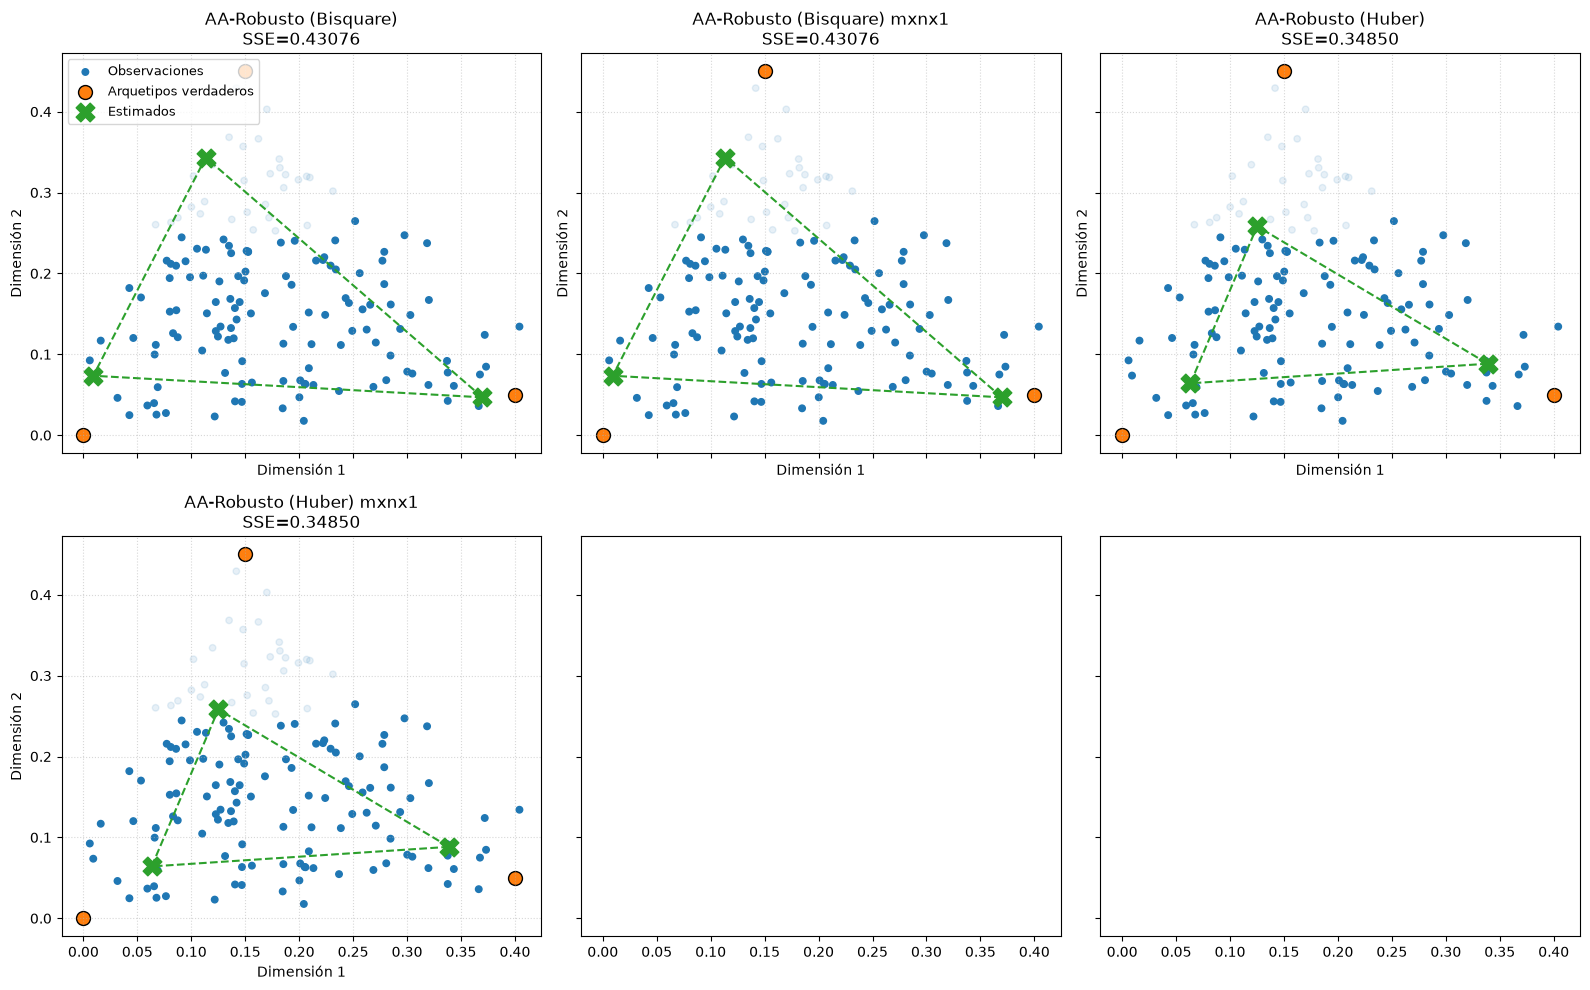

In [6]:
# Comparación visual de los métodos
Xhat_by_name = {
    "AA-Robusto (Bisquare)": Xhat_rob,
    "AA-Robusto (Bisquare) mxnx1": Xhat_rob_mxnx1,
    "AA-Robusto (Huber)": Xhat_rob_huber,
    "AA-Robusto (Huber) mxnx1": Xhat_rob_huber_mxnx1
}

Z_by_name = {
    "AA-Robusto (Bisquare)": Z_rob,
    "AA-Robusto (Bisquare) mxnx1": Z_rob_mxnx1,
    "AA-Robusto (Huber)": Z_rob_huber,
    "AA-Robusto (Huber) mxnx1": Z_rob_huber_mxnx1
}

fig, axes = plt.subplots(
    2, 3, figsize=(16, 10), sharex=True, sharey=True
)

axes_flat = axes.ravel()

for i, (name, Z_est) in enumerate(Z_by_name.items()):
    ax = axes_flat[i]

    # Mostrar punts observats amb opacitat/mida proporcional al seu pes
    ax.scatter(
        X[:, 0], X[:, 1],
        s=22, alpha=weights**10, label="Observaciones"
    )

    # Arquetipus reals
    ax.scatter(
        true_Z[:, 0], true_Z[:, 1],
        s=100, marker="o", edgecolors="black",
        label="Arquetipos verdaderos"
    )

    # Arquetipus estimats
    ax.scatter(
        Z_est[:, 0], Z_est[:, 1],
        s=180, marker="X", label="Estimados"
    )

    poly = np.vstack([Z_est, Z_est[0]])
    ax.plot(poly[:, 0], poly[:, 1], "--", color="tab:green",linewidth=1.5)

    ax.set_title(f"{name}\nSSE={sse(X, Xhat_by_name[name]):.5f}")
    ax.set_xlabel("Dimensión 1")
    ax.set_ylabel("Dimensión 2")
    ax.grid(True, linestyle=":", alpha=0.5)

# Colocamos la leyenda en el primer subplot para no saturar
axes.ravel()[0].legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()